In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyomo.environ as pyo

from utils import generate_simple_synthetic_data, generate_data_by_ids
from pyomo.environ import *

In [70]:
df = generate_data_by_ids(n_ids=50, n_prices_per_id=200)

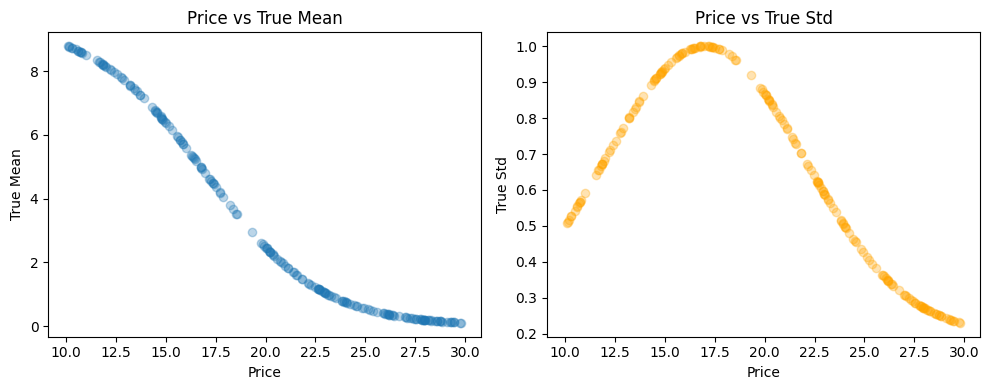

In [71]:
aux = df[df['id'] == 1]
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(aux['price'], aux['true_mean'], alpha=0.3)
plt.xlabel('Price')
plt.ylabel('True Mean')
plt.title('Price vs True Mean')

plt.subplot(1, 2, 2)
plt.scatter(aux['price'], aux['true_std'], alpha=0.3, color='orange')
plt.xlabel('Price')
plt.ylabel('True Std')
plt.title('Price vs True Std')

plt.tight_layout()
plt.show()

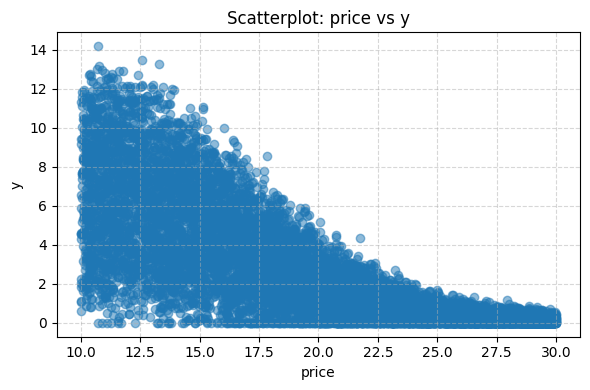

In [72]:
feature = 'price'
plt.figure(figsize=(6, 4))
plt.scatter(df[feature], df['y'], alpha=0.5)
plt.xlabel(feature)
plt.ylabel('y')
plt.title(f'Scatterplot: {feature} vs y')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

true_mean    0.973361
true_std     0.452726
x1           0.353900
x2           0.238897
id          -0.062826
price       -0.769632
Name: y, dtype: float64


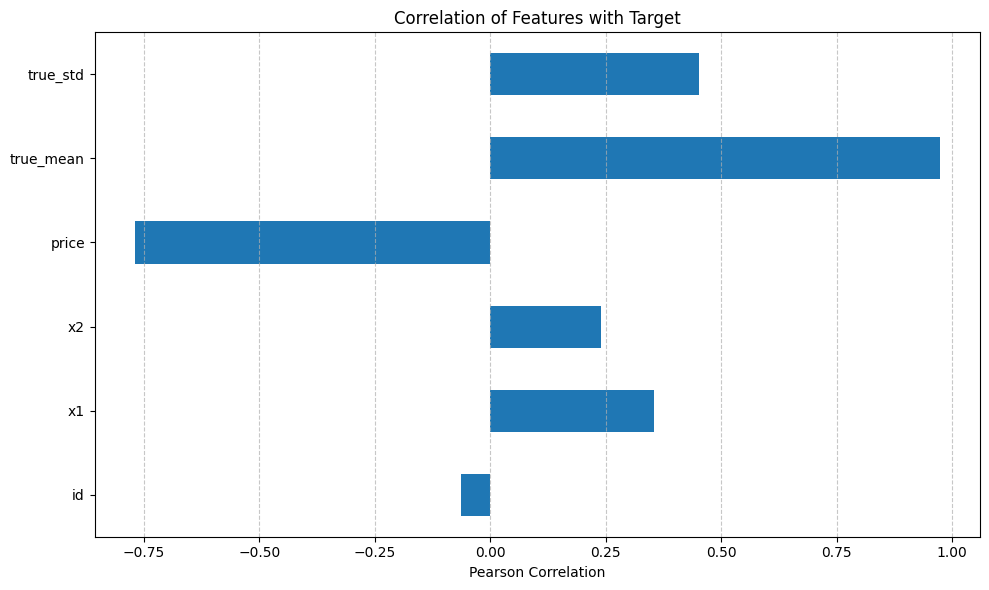

In [73]:
# Compute correlations of all columns with y
correlations = df.corr()['y'].drop('y')  # Drop self-correlation

# Display the correlations sorted by magnitude
print(correlations.sort_values(ascending=False))

# Plot
plt.figure(figsize=(10, 6))
correlations.plot(kind='barh')
plt.title('Correlation of Features with Target')
plt.xlabel('Pearson Correlation')
plt.grid(True, axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [74]:
X, y, true_mean, true_std = generate_simple_synthetic_data(n_samples=1000)

from sklearn.model_selection import train_test_split

# First split: train vs temp (val + test)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)

# Second split: val vs test (from temp)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

# Get the indices relative to the original dataset
val_ind = X_val.index
test_ind = X_test.index

print(X.head())
print(y.head())

         x1        x2      price
0  0.374540  0.185133  15.234114
1  0.950714  0.541901  14.939576
2  0.731994  0.872946  28.125092
3  0.598658  0.732225  14.990924
4  0.156019  0.806561  15.438995
0    4.164115
1    9.161541
2    0.433392
3    5.661846
4    5.218591
Name: y, dtype: float64


In [75]:
from distcl_cp import distcl
n_preds = 1
cl_tool = distcl(X, y, n_preds=n_preds, val_ind=val_ind, test_ind=test_ind)

In [76]:
model, preds_test, sd_test, y_test = cl_tool.train(n_hidden=1, n_nodes=50, iters=5000, drop=0.05, learning_rate=1e-3)

DistFCNN(
  (lin_layers): ModuleList(
    (0): Linear(in_features=3, out_features=50, bias=True)
  )
  (output_mean_layer): Linear(in_features=50, out_features=1, bias=True)
  (output_sd_layer): Linear(in_features=50, out_features=1, bias=True)
  (droput_layers): ModuleList(
    (0): Dropout(p=0.05, inplace=False)
  )
)
cuda:0
epoch 0 loss 159397.9375
epoch 500 loss 0.6823164224624634
epoch 1000 loss 0.6646851897239685
epoch 1500 loss 0.6551855206489563
epoch 2000 loss 0.3599333167076111
epoch 2500 loss 0.08663112670183182
epoch 3000 loss -0.000415992719354108
epoch 3500 loss -0.2084413468837738
epoch 4000 loss -0.24795569479465485
epoch 4500 loss -0.27604836225509644
NN fitting process finished with a validation GAUSSIANNLL loss of -0.43576666712760925 in epoch 4584


In [77]:
cons = cl_tool.constraint_build(model)
cons.to_csv('constraints.csv')

In [78]:
cons = pd.read_csv('constraints.csv', index_col=0)
cons

,intercept,layer,node,node_0,node_1,node_2,node_3,node_4,node_5,node_6,...,node_40,node_41,node_42,node_43,node_44,node_45,node_46,node_47,node_48,node_49
0,0.011405,0,0,-0.964275,0.602144,0.160949,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-0.432553,0,1,-0.478941,-0.208677,0.208394,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,-0.130610,0,2,-0.001176,0.442866,-0.069211,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0.250792,0,3,0.125124,-0.190765,-0.163352,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0.282416,0,4,-0.524505,-0.390718,-0.274050,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,-0.612446,0,5,-0.022979,0.173302,0.285214,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0.386316,0,6,-0.406320,-0.251577,0.232720,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,-0.517594,0,7,0.418599,-0.156526,0.361378,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,-0.198154,0,8,-0.093592,0.011810,0.438930,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,-0.259252,0,9,-0.513705,-0.366059,-0.174110,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [79]:
n_sc = 30
#contextual_var = trainer.X_test
contextual_var = X_test.iloc[:n_preds]
contextual_var.reset_index(drop=True, inplace=True)
contextual_var

,x1,x2,price
0,0.537396,0.643904,16.4334


In [88]:
contextual_var = pd.DataFrame([{
    'x1': 0.1317971241,
    'x2': 0.4232970643,
    'price': -0.6373367167
}])

contextual_var = contextual_var.reindex(sorted(contextual_var.columns), axis=1)
contextual_var

,price,x1,x2
0,-0.637337,0.131797,0.423297


In [80]:
contextual_var.columns.sort_values()

Index(['price', 'x1', 'x2'], dtype='object')

In [89]:
def model_definition(contextual_var, n_sc, n_preds):
    model = pyo.ConcreteModel()
    
    model.N = pyo.RangeSet(0,n_preds-1)
    model.W = pyo.RangeSet(1,n_sc) # scenarios

    pi = [1/n_sc for i in range(n_sc)]

    model.var_ind = pyo.Set(initialize=contextual_var.columns.sort_values())

    model.x = pyo.Var(model.var_ind, model.N) # price

    model.y = pyo.Var(pyo.Any, dense=False, domain=pyo.Reals)

    model.rent = pyo.Var(model.W, within=pyo.Reals) # rentabilidad per scenario

    #definition of the objective function
    def obj_expression(model):
        return sum(pi[w-1] * model.rent[w] for w in model.W)
    model.OBJ = pyo.Objective(rule=obj_expression, sense=pyo.maximize)

    #definition of the constraints
    def rent_expression(model, w):
        return model.rent[w] == sum(model.y['demand', n, w]*model.x['price',n] for n in model.N)
    model.rent_expression = pyo.Constraint(model.W, rule=rent_expression)

    #constraint for fixing contextual information
    def const9_rule(model,x_ind,n):
        if x_ind=='price':
            return pyo.Constraint.Skip
        else:
            return model.x[x_ind,n] == contextual_var.loc[n,x_ind]
    model.const9 = pyo.Constraint(model.var_ind, model.N, rule=const9_rule)

    P_max = 30
    # max price constraint for each price
    def max_price_expression(model, n):
        return model.x['price', n] <= P_max

    model.max_price_expression = pyo.Constraint(model.N, rule=max_price_expression)

    def min_price_expression(model, n):
        return model.x['price', n] >= 0
    model.min_price_expression = pyo.Constraint(model.N, rule=min_price_expression)

    return model



In [90]:
cl_tool.X_train

,price,x1,x2
0,-0.895965,1.546345,0.070600
1,-0.809500,-1.173433,0.985716
2,-1.524823,0.349871,-0.939854
3,-1.534217,1.612040,1.611929
4,1.387498,1.141570,1.461143
...,...,...,...
595,0.736581,-0.864103,-0.292632
596,0.162660,-0.776000,0.306845
597,-0.378042,0.312621,-1.335117
598,-1.206582,1.432034,1.504556


In [91]:
model = model_definition(contextual_var, n_sc, n_preds)
cl_tool.const_embed(opt_model=model, constaints=cons, outcome='demand', n_scenarios=n_sc)

In [92]:
for c in model.component_objects(Constraint, active=True):
    print(f"Constraint component: {c.name}")
    for index in c:
        print(f"  {index}: {c[index].expr}")

Constraint component: rent_expression
  1: rent[1]  ==  y[demand,0,1]*x[price,0]
  2: rent[2]  ==  y[demand,0,2]*x[price,0]
  3: rent[3]  ==  y[demand,0,3]*x[price,0]
  4: rent[4]  ==  y[demand,0,4]*x[price,0]
  5: rent[5]  ==  y[demand,0,5]*x[price,0]
  6: rent[6]  ==  y[demand,0,6]*x[price,0]
  7: rent[7]  ==  y[demand,0,7]*x[price,0]
  8: rent[8]  ==  y[demand,0,8]*x[price,0]
  9: rent[9]  ==  y[demand,0,9]*x[price,0]
  10: rent[10]  ==  y[demand,0,10]*x[price,0]
  11: rent[11]  ==  y[demand,0,11]*x[price,0]
  12: rent[12]  ==  y[demand,0,12]*x[price,0]
  13: rent[13]  ==  y[demand,0,13]*x[price,0]
  14: rent[14]  ==  y[demand,0,14]*x[price,0]
  15: rent[15]  ==  y[demand,0,15]*x[price,0]
  16: rent[16]  ==  y[demand,0,16]*x[price,0]
  17: rent[17]  ==  y[demand,0,17]*x[price,0]
  18: rent[18]  ==  y[demand,0,18]*x[price,0]
  19: rent[19]  ==  y[demand,0,19]*x[price,0]
  20: rent[20]  ==  y[demand,0,20]*x[price,0]
  21: rent[21]  ==  y[demand,0,21]*x[price,0]
  22: rent[22]  ==  y[d

In [93]:
opt = pyo.SolverFactory('gurobi')
opt.options['threads'] = 8
opt.options['NonConvex'] = 2
results = opt.solve(model, tee=True) 

Read LP format model from file C:\Users\danie\AppData\Local\Temp\tmpac9fwb78.pyomo.lp
Reading time = 0.01 seconds
x1: 186 rows, 165 columns, 746 nonzeros
Set parameter Threads to value 8
Set parameter NonConvex to value 2
Gurobi Optimizer version 12.0.2 build v12.0.2rc0 (win64 - Windows 11.0 (26100.2))

CPU model: 13th Gen Intel(R) Core(TM) i5-13500, instruction set [SSE2|AVX|AVX2]
Thread count: 14 physical cores, 20 logical processors, using up to 8 threads

Non-default parameters:
NonConvex  2
Threads  8

Optimize a model with 186 rows, 165 columns and 746 nonzeros
Model fingerprint: 0xf0585462
Model has 30 quadratic constraints
Variable types: 115 continuous, 50 integer (50 binary)
Coefficient statistics:
  Matrix range     [2e-04, 1e+03]
  QMatrix range    [1e+00, 1e+00]
  QLMatrix range   [1e+00, 1e+00]
  Objective range  [3e-02, 3e-02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [3e-02, 1e+03]
Presolve removed 67 rows and 74 columns
Presolve time: 0.00s
Presolved: 180 ro

In [94]:
for n in model.N:
    print("&"*50)
    print("Establecimiento ", n)
    opt_price = value(model.x['price',n])
    total_demand = 0
    for x in range(n_sc):
        total_demand += value(model.y['demand', n, x+1])
        #print("demand: ", value(model.y['demand', 0, x+1]))
    print("Average demand: ", total_demand/n_sc)
    opt_mean = value(model.y['demand', n,'mean'])
    opt_sd = value(model.y['demand', n,'sd'])
    opt_profit = value(model.OBJ)

    print(f"Optimal profit: {opt_profit}")
    print(f"Optimal demand: {total_demand}")
    print(f"Optimal price: {opt_price}")
    print(f"Optimal mean: {opt_mean}")
    print(f"Optimal sd: {opt_sd}")
    print("&"*50)

&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
Establecimiento  0
Average demand:  5.48691385025555
Optimal profit: 54.88301559667553
Optimal demand: 164.6074155076665
Optimal price: 10.002529125570172
Optimal mean: 0.599165896273169
Optimal sd: 0.5235569485537988
&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&&
